# 8.2a — Brand configuration to CV analysis

The registry maps implementation IDs to classes. One loader validates the real brand JSON and returns `(rubric, criteria)`. A direct loop runs those configured instances on one shared `CVInput`.

The example generates its own RGB image and uses a manual subject box as a fixture. No detector weights or VLM server are required. Upload integration, automatic subject detection, and the remaining scoring/VLM handoff are separate work.


In [3]:
import json
import sys
import tempfile
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageDraw

ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "brandlens").is_dir()
    and (path / "config" / "brand_standards.json").is_file()
)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

In [4]:
from brandlens.config import ConfigurationError, load_cv_config
from brandlens.cv.cv_input import CVInput
from brandlens.cv.subject.region import SubjectRegion

CONFIG_PATH = ROOT / "config" / "brand_standards.json"
SCHEMA_PATH = ROOT / "config" / "brand_standards.schema.json"

## Load and validate before processing images

The schema checks document structure. The loader uses the registry to check implementation IDs and declared measurement names; constructors validate settings. The returned rubric retains scoring parameters and VLM entries. The criterion objects are ready to use.


In [5]:
rubric, criteria = load_cv_config(CONFIG_PATH)
print("Schema:", rubric["schema_version"])
print("Configured CV criteria:", tuple(criteria))
print(
    "Needs a subject region:",
    any(c.input_requirements()["reliable_subject_region"] for c in criteria.values()),
)
vlm_entries = [entry for entry in rubric["criteria"] if entry["method"] == "vlm"]
print("VLM entries retained:", [entry["criterion_id"] for entry in vlm_entries])
print("Brightness instance:", type(criteria["exposure_brightness"]).__name__)
print(
    "Palette passed from the brand JSON:",
    criteria["color_palette_fit"].settings["brand_palette"],
)

Schema: 1.1.0
Configured CV criteria: ('exposure_brightness', 'contrast', 'color_palette_fit', 'framing_subject_position', 'sharpness_subject_emphasis')
Needs a subject region: True
VLM entries retained: ['tone_approachability']
Brightness instance: BrightnessCriterion
Palette passed from the brand JSON: ['#004977', '#D03027', '#FFFFFF']


## Run all five criteria on the same input

The clean image is analyzed. The annotated copy is only for display. All settings and output names come from the JSON and registered criterion specifications.

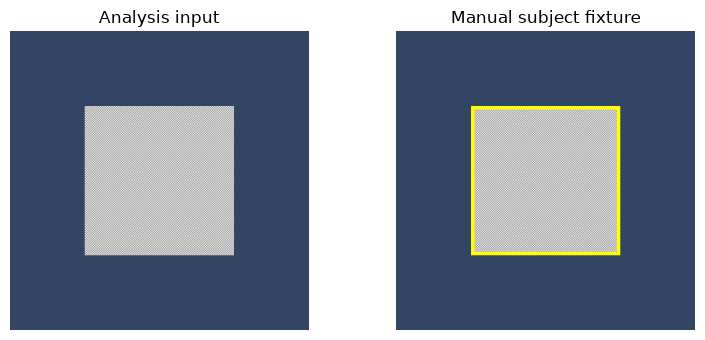

,criterion,status,measurement_count
0,exposure_brightness,available,3
1,contrast,available,4
2,color_palette_fit,available,2
3,framing_subject_position,available,10
4,sharpness_subject_emphasis,available,7


,criterion,measurement,value,unit
0,exposure_brightness,mean_luminance,99.000000,grayscale_0_255
1,contrast,luminance_std,58.122715,grayscale_0_255
2,color_palette_fit,palette_distance,14.318438,delta_e_76
3,framing_subject_position,center_distance,0.000000,image_diagonal_fraction
4,sharpness_subject_emphasis,subject_laplacian_variance,78400.000000,intensity_squared


In [6]:
pixels = np.empty((256, 256, 3), dtype=np.uint8)
pixels[:] = (50, 70, 100)
checker = np.where(np.indices((128, 128)).sum(axis=0) % 2, 230, 160).astype(np.uint8)
pixels[64:192, 64:192] = checker[..., None]
image = Image.fromarray(pixels)
subject = SubjectRegion(
    0.25,
    0.25,
    0.75,
    0.75,
    reliable=True,
    source="manual_synthetic_fixture",
)
annotated = image.copy()
ImageDraw.Draw(annotated).rectangle((64, 64, 191, 191), outline="yellow", width=3)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, picture, title in zip(
    axes, (image, annotated), ("Analysis input", "Manual subject fixture")
):
    ax.imshow(picture)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.show()
annotated.close()

data = CVInput(image, subject)
results = {cid: criterion.analyze(data) for cid, criterion in criteria.items()}
display(
    pd.DataFrame(
        [
            {
                "criterion": cid,
                "status": row["status"],
                "measurement_count": len(row["measurements"]),
            }
            for cid, row in results.items()
        ]
    )
)
selected_metrics = {
    "exposure_brightness": "mean_luminance",
    "contrast": "luminance_std",
    "color_palette_fit": "palette_distance",
    "framing_subject_position": "center_distance",
    "sharpness_subject_emphasis": "subject_laplacian_variance",
}
display(
    pd.DataFrame(
        [
            {
                "criterion": cid,
                "measurement": metric,
                "value": results[cid]["measurements"][metric],
                "unit": results[cid]["units"][metric],
            }
            for cid, metric in selected_metrics.items()
        ]
    )
)

## Change a measurement setting in a JSON file

Write a temporary variant of the real rubric with `near_black_max = 80`, then load it through the same file API. The tracked rubric is not modified. The blue background has grayscale intensity 67, so it becomes near-black under the higher cutoff. The mean intensity is unaffected.

In [7]:
changed_document = json.loads(CONFIG_PATH.read_text())
brightness_config = next(
    c
    for c in changed_document["criteria"]
    if c["criterion_id"] == "exposure_brightness"
)
brightness_config["settings"]["near_black_max"] = 80
with tempfile.TemporaryDirectory() as directory:
    changed_path = Path(directory) / "changed_brand.json"
    changed_path.write_text(json.dumps(changed_document, indent=2))
    changed_rubric, changed_criteria = load_cv_config(
        changed_path, schema_path=SCHEMA_PATH
    )
    changed_result = changed_criteria["exposure_brightness"].analyze(data)

baseline = results["exposure_brightness"]
display(
    pd.DataFrame(
        [
            {
                "near_black_max": row["method"]["parameters"]["near_black_max"],
                "near_black_fraction": row["measurements"]["near_black_fraction"],
                "mean_luminance": row["measurements"]["mean_luminance"],
            }
            for row in (baseline, changed_result)
        ]
    )
)

,near_black_max,near_black_fraction,mean_luminance
0,10,0.00,99.0
1,80,0.75,99.0


## Reject unsupported configuration before analysis

These failures occur in `load_cv_config()`, before an image is passed to any criterion. The messages identify the criterion and unsupported field.


In [8]:
invalid_settings = deepcopy(changed_document)
invalid_settings["criteria"][0]["settings"]["near_black_typo"] = 10
try:
    load_cv_config(invalid_settings, schema_path=SCHEMA_PATH)
except ConfigurationError as error:
    print("Unsupported setting:", error)

invalid_measurement = deepcopy(changed_document)
invalid_measurement["criteria"][0]["required_measurements"] = ["unknown_measurement"]
try:
    load_cv_config(invalid_measurement, schema_path=SCHEMA_PATH)
except ConfigurationError as error:
    print("Unsupported measurement:", error)

Unsupported setting: exposure_brightness: Unknown settings: near_black_typo
Unsupported measurement: exposure_brightness: unsupported measurements: unknown_measurement


## Missing subjects preserve global results

The loop passes the same input to every criterion. It does not invent a subject box. Here the subject-dependent criteria report review states while brightness, contrast, and palette measurements remain available. An upstream detector/selector supplies the shared subject region during full-pipeline integration.


In [9]:
data_without_subject = CVInput(
    image, subject_unavailable_reason="No reliable primary subject was supplied."
)
without_subject = {
    cid: criterion.analyze(data_without_subject) for cid, criterion in criteria.items()
}
display(
    pd.DataFrame(
        [
            {
                "criterion": cid,
                "status": row["status"],
                "reason": "; ".join(row["reasons"]),
            }
            for cid, row in without_subject.items()
        ]
    )
)

,criterion,status,reason
0,exposure_brightness,available,
1,contrast,available,
2,color_palette_fit,available,
3,framing_subject_position,unavailable_needs_review,No reliable primary subject was supplied.
4,sharpness_subject_emphasis,unavailable_needs_review,No reliable primary subject was supplied.


## Existing scoring boundary

The existing scorer already consumes brightness/contrast outputs. This optional call demonstrates that compatible boundary using the draft rubric's existing thresholds; it does not establish calibrated brand acceptance.

Palette scoring still needs a configured distance threshold. Framing/sharpness scoring must adopt the native measurement/parameter names documented in `docs/8_2a_scoring_handoff.md`. The VLM entry is preserved but no model is run in this notebook.

In [10]:
from brandlens.scoring import score_image

scored = score_image(
    rubric,
    cv_results=results,
    criterion_ids=["exposure_brightness", "contrast"],
)
display(
    pd.DataFrame(
        [
            {
                "criterion": row.criterion_id,
                "score": row.score,
                "availability": row.availability,
            }
            for row in scored.criteria
        ]
    )
)
print("Overall for these two criteria:", scored.overall_score)
image.close()

,criterion,score,availability
0,exposure_brightness,100.0,ok
1,contrast,100.0,ok


Overall for these two criteria: 100.0
